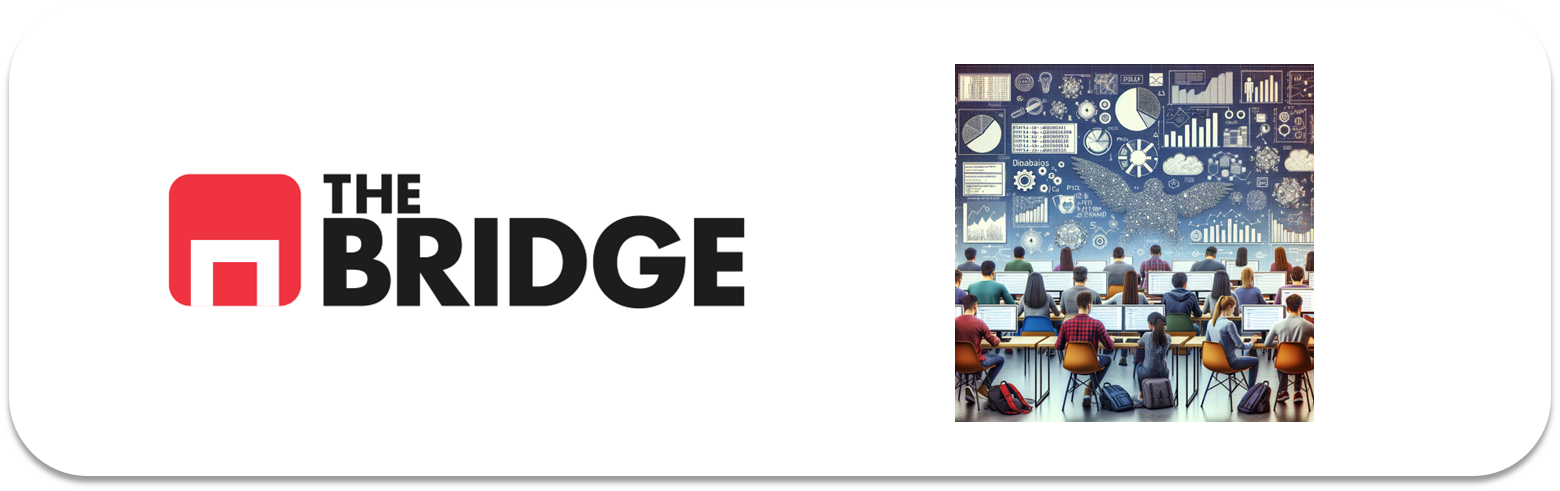

## PRÁCTICA OBLIGATORIA: **Clasificación y Regresión Logística**

* La práctica obligatoria de esta unidad consiste en modelar la supervivencia en el Titanic, por fin, además de una parte adicional multiclase. Descarga este notebook en tu ordenador y trabaja en local. Ten en cuenta que tendrás que descargar los directorios de imágenes y datos adicionales, si los hubiera.
* Recuerda que debes subirla a tu repositorio personal antes de la sesión en vivo para que puntúe adecuadamente.  
* Recuerda también que no es necesario que esté perfecta, solo es necesario que se vea el esfuerzo. 
* Esta práctica se resolverá en la sesión en vivo correspondiente y la solución se publicará en el repo del curso. 

### Ejercicio 0

Importa los paquetes y módulos que necesites a lo largo del notebook.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix,
                             ConfusionMatrixDisplay, roc_curve, roc_auc_score)

sns.set_theme(style='whitegrid')

### Indicaciones

A continuación tienes las indicaciones para hacer el modelado. No necesariamente tienes que seguirlas al pie de la letra, porque a partir de ahora las prácticas obligatorias dejarán de ser mayormente guiadas por ejercicios y serán más de libre desarrollo, aunque con objetivos específicos, claros y determinados. 

En concreto se pide hacer un modelo de regresión logística, evaluarlo contra un dataset de test reservado del original mostrando las métricas propias de los problemas de clasificación, la matriz de confusión y la curva ROC. Además se pide comparar las predicciones con los valores reales y al final adaptar el modelo a un problema multiclase.

Los pasos para guiar el trabajo:
1. Carga el dataset del Titanic. 
2. Deshazte de las variables que no vayas a usar. Limpia lo que creas necesario pero no hagas imputaciones.
3. Escoge y analiza la variable target de forma gráfica y razona sobre el impacto de la distribución en los resultados esperados. Ten en cuenta que lo que queremos es poder predecir si un pasajero sobrevivirá.
4. Haz el split en train y test que creas conveniente pero asegurándote que ambos conjuntos tienen un reparto similar de pasajeros embarcados en las tres ciudades.
5. Construye las parejas X,y de train y test.
6. Ahora sí imputa los nulos con medias y modas en la X de train. Guarda esas medias que necesitarás en la parte de test.
7. Haz un mini-EDA, selecciona las features que quieres quedarte y por qué.
8. Trata las variables para que funcionen lo mejor posible en el modelo.
9. Construye un modelo de regresión logística.
10. EXTRA: Analiza si lo crees conveniente los pesos y la importancia de las features.
11. Procesa el dataset de Test para que puedas usarlo en la evaluación 
12. Evalúa tu modelo contra el dataset de test y train. Obtén las matrices de confusión y las métricas que creas adecuadas. Haz una pequeña valoración de su capacidad de generalización.
13. EXTRA: Halla la probabilidad de supervivencia de un hombre de entre 30 y 40 años, que embarcó en Southampton en segunda clase, viajaba solo y no pagó el billete. PISTA: En este caso tendrás que calcular varias probabilidades y hacer la media de ellas.
14. EXTRA: Aprovecha todo el trabajo haciendo un único cambio en el target, ahora será la clase del viajero. Cambia el target quitándolo de X_train, X_test y añade a estos el target anterior. El resto no deberías cambiarlo. Entrena y evalúa el modelo solo con el classification_report.  



#### 1. Carga el dataset del Titanic. 

In [2]:

df = pd.read_csv("../data/titanic.csv")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


In [3]:
print(df.isnull().sum())

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64


#### 2. Deshazte de las variables que no vayas a usar. Limpia lo que creas necesario pero no hagas imputaciones.

Eliminamos deck porque tiene un porcentaje muy alto de de nulos. Para age crearemos nueva variable missing_age y para embark_town tenemos solo 2 nulos y nos desharemos de esos pasajeros.


In [4]:
#Eliminamos, alive, embarked, who, adult_male, who y alone porque son variables redundantes. 
df = df = df.drop(columns=['alive', 'class', 'embarked', 'who', 'adult_male', 'alone', 'deck'])
#Eliminamos los dos pasajeros sin embark_town
df = df.dropna(subset=['embark_town']).reset_index(drop=True)
#Creamos la nueva variable missing_age. Son bastantes datos que no nos podemos permitir perder.
df['missing_age']= df['age'].isnull().map({True: 1, False: 0})

#### 3. Escoge y analiza la variable target de forma gráfica y razona sobre el impacto de la distribución en los resultados esperados. Ten en cuenta que lo que queremos es poder predecir si un pasajero sobrevivirá.

La variable target va a ser ``survived`` porque queremos predecir si el pasajero sobrevirá o no

In [5]:
print(df['survived'].value_counts())
print(df['survived'].value_counts(normalize=True).round(3))

survived
0    549
1    340
Name: count, dtype: int64
survived
0    0.618
1    0.382
Name: proportion, dtype: float64


Vamos a ver su distribución

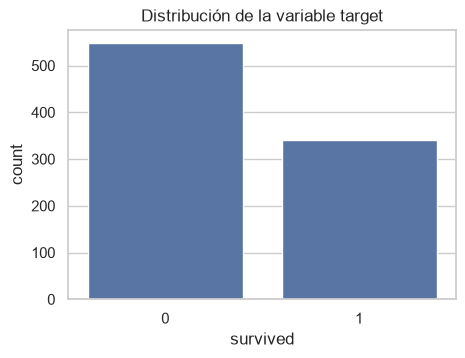

In [6]:
fig, ax = plt.subplots(figsize=(5, 3.5))
sns.countplot(data=df, x='survived', ax=ax)
ax.set_xticks([0, 1])
ax.set_xticklabels(['0', '1'])
ax.set_title('Distribución de la variable target')
plt.show()

Es un desbalance moderado (61 vs 39%) lo que hace necesario. Un modelo que predijera siempre "muere" ya tendría 62 % de accuracy. Por eso hay que mirar también precision, recall y F1 de la clase 1 (sobrevive), la matriz de confusión y tal vez, el AUC de la curva ROC. Es de esperar que el modelo acierte algo mejor la clase mayoritaria (0) que la minoritaria (1).

In [7]:
df.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embark_town      0
missing_age      0
dtype: int64

#### 4. Haz el split en train y test que creas conveniente pero asegurándote que ambos conjuntos tienen un reparto similar de pasajeros embarcados en las tres ciudades.

In [8]:
train_df, test_df = train_test_split(df, test_size=0.2, random_state=42, stratify=df['embark_town'])

#Comprobamos que la estratificación ha funcionado
pd.DataFrame({
    'train': train_df['embark_town'].value_counts(normalize=True),
    'test': test_df['embark_town'].value_counts(normalize=True),
}).round(3)

,train,test
embark_town,,
Southampton,0.724,0.725
Cherbourg,0.188,0.191
Queenstown,0.087,0.084


#### 5. Construye las parejas X,y de train y test.

In [9]:
X_train = train_df.drop(columns='survived')
y_train = train_df['survived']
X_test = test_df.drop(columns='survived')
y_test = test_df['survived']

#Comprpbamos el tamaño
print(X_train.shape, X_test.shape)

(711, 8) (178, 8)


In [10]:
X_train

,pclass,sex,age,sibsp,parch,fare,embark_town,missing_age
46,3,male,NaN,1,0,15.500,Queenstown,1
229,1,female,35.0,1,0,83.475,Southampton,0
656,3,female,32.0,1,1,15.500,Queenstown,0
886,3,female,NaN,1,2,23.450,Southampton,1
808,1,female,33.0,1,0,53.100,Southampton,0
...,...,...,...,...,...,...,...,...
221,3,male,51.0,0,0,8.050,Southampton,0
166,3,female,45.0,1,4,27.900,Southampton,0
122,2,female,32.5,0,0,13.000,Southampton,0
149,2,male,51.0,0,0,12.525,Southampton,0


#### 6. Ahora sí imputa los nulos con medias y modas en la X de train. Guarda esas medias que necesitarás en la parte de test.

In [11]:
#Imputamos los nulos con la media de age segun la clase a la que pertence nuestro pasajero

X_train['age'] = X_train['age'].fillna(df.groupby('pclass')['age'].transform('mean'))

#### 7. Haz un mini-EDA, selecciona las features que quieres quedarte y por qué.

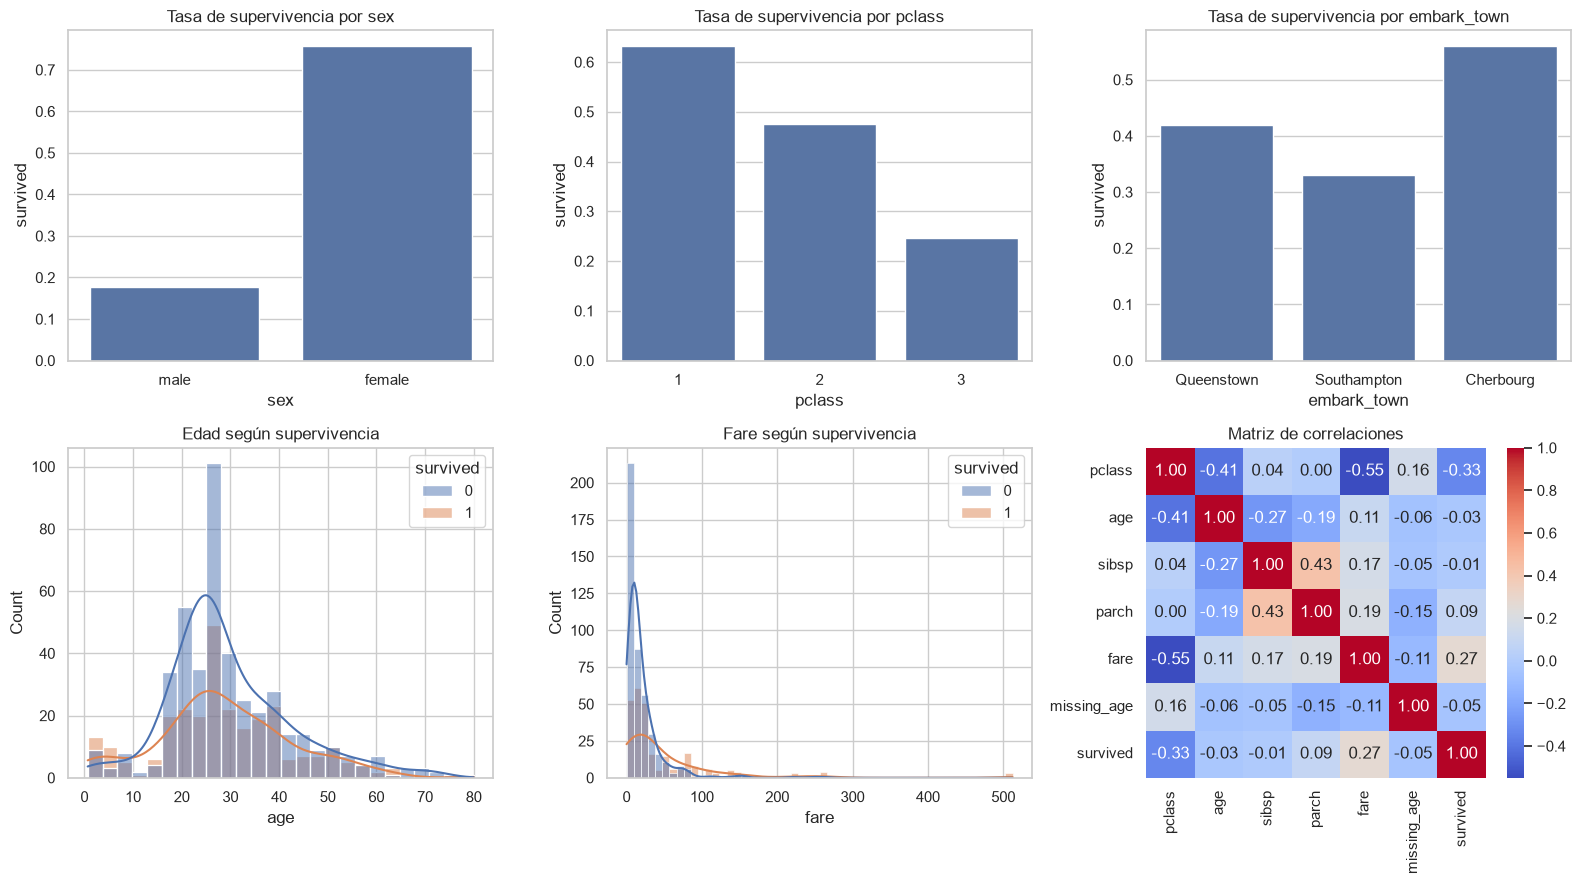

Supervivencia según missing_age:
missing_age
0    0.393
1    0.333
Name: survived, dtype: float64


In [12]:
EDA = X_train.assign(survived=y_train)

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for ax, col in zip(axes.flat[:3], ['sex', 'pclass', 'embark_town']):
    sns.barplot(data=EDA, x=col, y='survived', errorbar=None, ax=ax)
    ax.set_title(f'Tasa de supervivencia por {col}')

sns.histplot(data=EDA, x='age', hue='survived', kde=True, ax=axes[1, 0])
axes[1, 0].set_title('Edad según supervivencia')

sns.histplot(data=EDA, x='fare', hue='survived', kde=True, ax=axes[1, 1])
axes[1, 1].set_title('Fare según supervivencia')

sns.heatmap(EDA.select_dtypes('number').corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=axes[1, 2])
axes[1, 2].set_title('Matriz de correlaciones')

plt.tight_layout()
plt.show()

print('Supervivencia según missing_age:')
print(EDA.groupby('missing_age')['survived'].mean().round(3))


La supervivencia fue un poco menor en aquellos individuos en los que falta la edad. 0,16 de correlacion entre pclass y age, lo que indica una relación lineal positiva débil. Esto significa que a medida que el número de la clase aumenta (pasando de 1.ª a 3.ª clase), la probabilidad de que falte el dato de la edad sube ligeramente.

Fare tiene una distribución asimétrica. 

#### 8. Trata las variables para que funcionen lo mejor posible en el modelo.

- `fare` → `log1p` para reducir la asimetría.
- Categóricas (`pclass`, `sex`, `embark_town`) → *one-hot*, quitando una categoría de referencia por variable
  (primera clase, mujer, Cherbourg) para evitar redundancia.
- Numéricas (`age`, `sibsp`, `parch`, `fare`) → `StandardScaler` 

In [13]:
# 1. Transformación logarítmica
X_train['fare'] = np.log1p(X_train['fare'])

# 2. One-Hot Encoding X_train de las categóricas
cat_cols = ['pclass', 'sex', 'embark_town']
X_train = pd.get_dummies(X_train, columns=cat_cols, drop_first=True, dtype=int)

# 3. Estandarización de las numéricas
num_cols = ['age', 'sibsp', 'parch', 'fare']
scaler = StandardScaler()
X_train[num_cols] = scaler.fit_transform(X_train[num_cols])

X_train.head()

,age,sibsp,parch,fare,missing_age,pclass_2,pclass_3,sex_male,embark_town_Queenstown,embark_town_Southampton
46,-0.314522,0.510583,-0.483229,-0.135867,1,0,1,1,1,0
229,0.430511,0.510583,-0.483229,1.556601,0,0,0,0,0,1
656,0.203813,0.510583,0.828129,-0.135867,0,0,1,0,1,0
886,-0.314522,0.510583,2.139486,0.271701,1,0,1,0,0,1
808,0.279379,0.510583,-0.483229,1.094779,0,0,0,0,0,1


Tenemos que aplicar todo lo que hemos hecho sobre x_test también

In [ ]:
X_test['age'] = X_test['age'].fillna(df.groupby('pclass')['age'].transform('mean'))
X_test['fare'] = np.log1p(X_test['fare'])
X_test = pd.get_dummies(X_test, columns=cat_cols, drop_first=True, dtype=int)
X_test[num_cols] = scaler.fit_transform(X_test[num_cols])

#### 9. Construye un modelo de regresión logística.

In [16]:
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",42
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in 

### EXTRA

#### I. Matrices de confusión

In [19]:
pred_train = log_reg.predict(X_train)
pred_test = log_reg.predict(X_test)

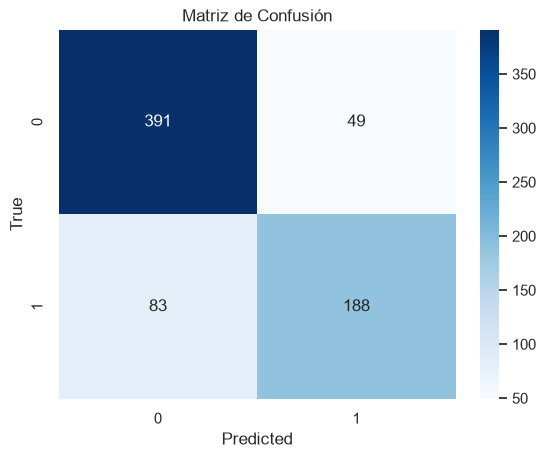

              precision    recall  f1-score   support

           0       0.82      0.89      0.86       440
           1       0.79      0.69      0.74       271

    accuracy                           0.81       711
   macro avg       0.81      0.79      0.80       711
weighted avg       0.81      0.81      0.81       711



In [ ]:
# TRAIN Calcular la matriz de confusión
conf_matrix = confusion_matrix(y_train, pred_train)

# Visualizar la matriz de confusión
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusión')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Generar el informe de clasificación
print(classification_report(y_train, pred_train))

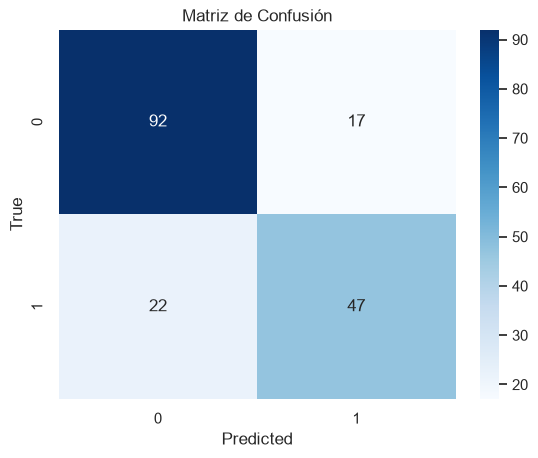

              precision    recall  f1-score   support

           0       0.81      0.84      0.83       109
           1       0.73      0.68      0.71        69

    accuracy                           0.78       178
   macro avg       0.77      0.76      0.77       178
weighted avg       0.78      0.78      0.78       178



In [21]:
# TEST Calcular la matriz de confusión
conf_matrix = confusion_matrix(y_test, pred_test)

# Visualizar la matriz de confusión
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusión')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

# Generar el informe de clasificación
print(classification_report(y_test, pred_test))

#### II. AUC

In [25]:
#Codigo reutilizado de una de las soluciones a los ejercicios

AUROC: 0.85


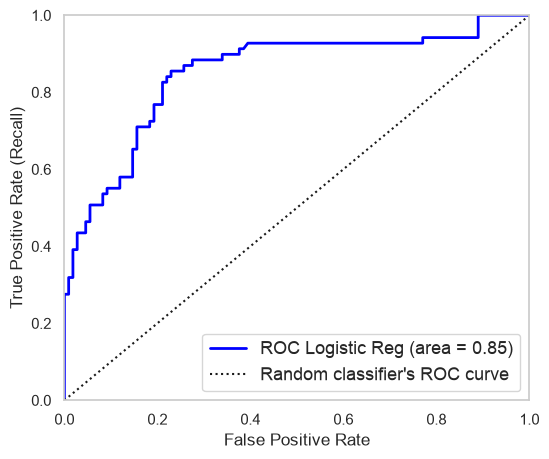

In [22]:
from sklearn.metrics import roc_curve, auc
scores = log_reg.predict_proba(X_test)
fpr, tpr, thresholds = roc_curve(y_test, scores[:,1])
roc_auc = auc(fpr,tpr)
print("AUROC: %.2f" %(roc_auc))
plt.figure(figsize=(6, 5))  
plt.plot(fpr, tpr, linewidth=2, color= "blue", label=f"ROC Logistic Reg (area = {roc_auc:0.2f})")
plt.plot([0, 1], [0, 1], 'k:', label="Random classifier's ROC curve")
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate (Recall)')
plt.grid()
plt.axis([0, 1, 0, 1])
plt.legend(loc="lower right", fontsize=13)

,coefs
sibsp,-0.429088
sex_male,-2.616076
pclass_3,-1.279094
pclass_2,-0.335414
parch,-0.186124
missing_age,-0.036096
fare,0.481858
embark_town_Southampton,-0.335780
embark_town_Queenstown,0.079075
age,-0.402347


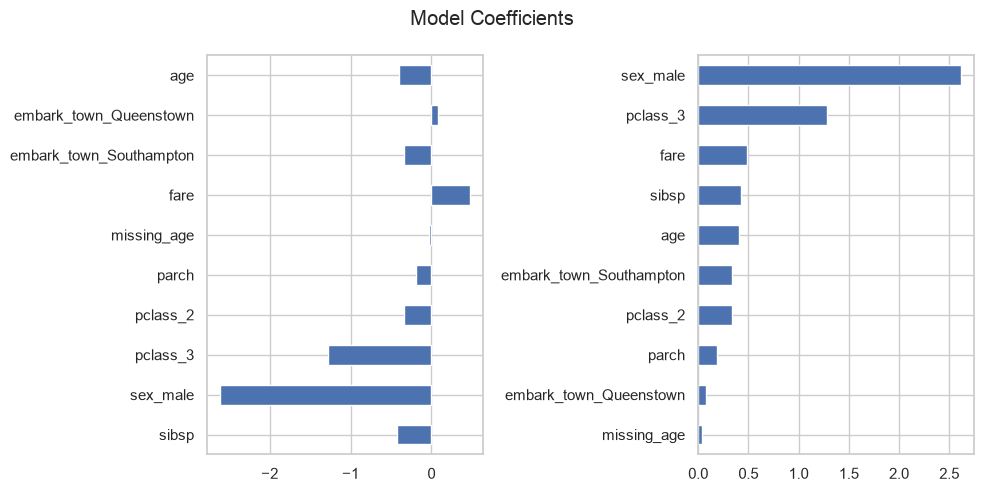

In [ ]:
def show_coefs(model, figsize=(10, 5)):
    df_coef = pd.DataFrame(model.coef_[0], index=model.feature_names_in_, columns=["coefs"])

    fig, ax = plt.subplots(1, 2, figsize=figsize)
    df_coef.plot(kind="barh", ax=ax[0], legend=False)
    df_coef.abs().sort_values(by="coefs").plot(kind="barh", ax=ax[1], legend=False)
    fig.suptitle("Model Coefficients")

    fig.tight_layout()

    return df_coef


show_coefs(log_reg)